In [121]:
"""
Project: Customer Segmentation and Predictive Modelling
Author: Ayush Yadav
Description: End-to-end data pipeline covering cleaning, feature engineering, 
             K-Means clustering, and Random Forest regression on insurance/customer data.
Tools: Python, Pandas, Scikit-Learn, Matplotlib, Seaborn
"""

'\nProject: Customer Segmentation and Predictive Modelling\nAuthor: Ayush Yadav\nDescription: End-to-end data pipeline covering cleaning, feature engineering, \n             K-Means clustering, and Random Forest regression on insurance/customer data.\nTools: Python, Pandas, Scikit-Learn, Matplotlib, Seaborn\n'

In [98]:
# =========================================================================
# TASK 1: Import Pandas and NumPy for data manipulation and numerical analysis
# =========================================================================
import pandas as pd
import numpy as np

In [99]:
# -------------------------------------------------------------------------
# Step 1: Load the Dataset
# What this does: Reads our raw CSV file into a pandas DataFrame so we can 
# manipulate and analyze it in memory.
# -------------------------------------------------------------------------
print("--- 1. LOADING DATASET ---")
df = pd.read_csv('customer_segmentation_data.csv')
print(f"Original dataset shape: {df.shape}\n")

--- 1. LOADING DATASET ---
Original dataset shape: (53503, 20)



In [100]:
# -------------------------------------------------------------------------
# Step 2: Check for Missing Values and Duplicates
# What this does: Ensures data integrity. Checking for nulls ensures our 
# machine learning models don't crash, and checking for duplicate Customer IDs 
# prevents biasing our clustering/predictions.
# -------------------------------------------------------------------------
print("--- 2. CHECKING MISSING VALUES & DUPLICATES ---")
missing_values = df.isnull().sum().sum()
print(f"Total missing values found: {missing_values}")

duplicate_count = df.duplicated(subset=['Customer ID']).sum()
print(f"Total duplicate Customer IDs found: {duplicate_count}")

# If there were duplicates, we'd drop them like this:
# df = df.drop_duplicates(subset=['Customer ID'])
print("Data integrity check passed.\n")

--- 2. CHECKING MISSING VALUES & DUPLICATES ---
Total missing values found: 0
Total duplicate Customer IDs found: 13244
Data integrity check passed.



In [101]:
# -------------------------------------------------------------------------
# Step 3: Handle Data Types & Formatting (Dates & Numbers)
# What this does: Converts string date columns into proper pandas datetime 
# objects so we can extract time-based features (like customer tenure) later. 
# Also confirms our numeric columns are properly typed.
# -------------------------------------------------------------------------
print("--- 3. FORMATTING DATA TYPES ---")

# Convert Purchase History from string to datetime
df['Purchase History'] = pd.to_datetime(df['Purchase History'], format='%d-%m-%Y', errors='coerce')

# Verify numerical columns
numeric_cols = ['Age', 'Income Level', 'Coverage Amount', 'Premium Amount']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Date and numeric columns successfully formatted.")
print(df[['Customer ID', 'Purchase History', 'Income Level']].head(3))
print("\n")

--- 3. FORMATTING DATA TYPES ---


Date and numeric columns successfully formatted.
   Customer ID Purchase History  Income Level
0        84966       2018-10-04         70541
1        95568       2018-06-11         54168
2        10544       2021-05-06         73899




In [102]:
# -------------------------------------------------------------------------
# Step 4: Inspect Categorical Variables
# What this does: Checks unique values for categorical columns to spot any 
# unexpected typos, mixed cases, or weird formatting that could mess up 
# one-hot encoding or grouping later.
# -------------------------------------------------------------------------
print("--- 4. INSPECTING CATEGORICAL VARIABLES ---")
categorical_cols = ['Gender', 'Marital Status', 'Education Level', 'Policy Type', 'Segmentation Group']

for col in categorical_cols:
    print(f"Unique values in '{col}': {df[col].unique()}")

print("\nData cleaning script completed successfully! Ready for Feature Engineering.")

--- 4. INSPECTING CATEGORICAL VARIABLES ---
Unique values in 'Gender': <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Unique values in 'Marital Status': <StringArray>
['Married', 'Widowed', 'Single', 'Divorced', 'Separated']
Length: 5, dtype: str
Unique values in 'Education Level': <StringArray>
[   'Associate Degree',           'Doctorate',   'Bachelor's Degree',
     'Master's Degree', 'High School Diploma']
Length: 5, dtype: str
Unique values in 'Policy Type': <StringArray>
['Group', 'Family', 'Individual', 'Business']
Length: 4, dtype: str
Unique values in 'Segmentation Group': <StringArray>
['Segment5', 'Segment3', 'Segment2', 'Segment4', 'Segment1']
Length: 5, dtype: str

Data cleaning script completed successfully! Ready for Feature Engineering.


In [103]:
# =========================================================================
# TASK 2: FEATURE ENGINEERING
# =========================================================================
print("\n--- STARTING TASK 2: FEATURE ENGINEERING ---")


--- STARTING TASK 2: FEATURE ENGINEERING ---


In [104]:
# -------------------------------------------------------------------------
# Step 1: Handle Duplicate Customer IDs
# What this does: Keeps only the first occurrence of each Customer ID so 
# our clustering and models don't overweight repeat entries for the same person.
# -------------------------------------------------------------------------
initial_rows = len(df)
df = df.drop_duplicates(subset=['Customer ID'], keep='first')
print(f"Dropped {initial_rows - len(df)} duplicate rows. Clean dataset shape: {df.shape}")

Dropped 13244 duplicate rows. Clean dataset shape: (40259, 20)


In [105]:
# -------------------------------------------------------------------------
# Step 2: Create Customer Tenure (Time-based feature)
# What this does: Calculates the number of days between each customer's 
# purchase history date and a fixed reference date (e.g., today's date).
# -------------------------------------------------------------------------
# Using today's date (or max date in dataset as reference)
reference_date = pd.to_datetime('2026-10-30')
df['Customer_Tenure_Days'] = (reference_date - df['Purchase History']).dt.days
print("Created feature: 'Customer_Tenure_Days'")

Created feature: 'Customer_Tenure_Days'


In [106]:
# -------------------------------------------------------------------------
# Step 3: Create Premium-to-Coverage Ratio (Financial feature)
# What this does: Measures the cost efficiency/risk profile by dividing 
# the premium amount by the total coverage amount.
# -------------------------------------------------------------------------
# Adding a small epsilon (1e-6) to avoid division by zero if coverage is 0
df['Premium_to_Coverage_Ratio'] = df['Premium Amount'] / (df['Coverage Amount'] + 1e-6)
print("Created feature: 'Premium_to_Coverage_Ratio'")

Created feature: 'Premium_to_Coverage_Ratio'


In [107]:
# -------------------------------------------------------------------------
# Step 4: Create Age Brackets (Demographic feature)
# What this does: Bins continuous age into meaningful generational cohorts 
# to help models capture non-linear age-based trends.
# -------------------------------------------------------------------------
bins = [17, 30, 45, 60, 75]
labels = ['Young Adult', 'Adult', 'Middle-Aged', 'Senior']
df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Convert Age_Group to dummy/one-hot columns for modeling later
df = pd.get_dummies(df, columns=['Age_Group'], drop_first=True)
print("Created feature: 'Age_Group' and applied one-hot encoding.")

Created feature: 'Age_Group' and applied one-hot encoding.


In [108]:
# -------------------------------------------------------------------------
# Step 5: Encode Key Categorical Variables
# What this does: Converts text-based categories (like Gender, Marital Status, 
# and Policy Type) into numerical binary columns (one-hot encoding) so 
# distance-based clustering algorithms like K-Means can read them.
# -------------------------------------------------------------------------
categorical_to_encode = ['Gender', 'Marital Status', 'Policy Type', 'Preferred Communication Channel']
df = pd.get_dummies(df, columns=categorical_to_encode, drop_first=True)

print(f"Categorical variables encoded. Final feature-engineered shape: {df.shape}")
print("\nTask 2 completed successfully! Ready for Task 3: Customer Segmentation (K-Means).")

Categorical variables encoded. Final feature-engineered shape: (40259, 33)

Task 2 completed successfully! Ready for Task 3: Customer Segmentation (K-Means).


In [109]:
pip install scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [110]:
# Check for any NaNs in our cluster features and drop them
cluster_features = [
    'Age', 'Income Level', 'Coverage Amount', 'Premium Amount', 
    'Customer_Tenure_Days', 'Premium_to_Coverage_Ratio'
]

# Drop rows where any of these specific features have NaN values
df = df.dropna(subset=cluster_features)
print(f"Cleaned dataset shape for clustering: {df.shape}")

Cleaned dataset shape for clustering: (17101, 33)


In [111]:
# =========================================================================
# TASK 3: CUSTOMER SEGMENTATION (K-MEANS CLUSTERING)
# =========================================================================
print("\n--- STARTING TASK 3: CUSTOMER SEGMENTATION ---")

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns


--- STARTING TASK 3: CUSTOMER SEGMENTATION ---


In [112]:
# -------------------------------------------------------------------------
# Step 1: Select Features for Clustering
# What this does: Picks the core numerical and financial metrics that 
# represent our customers' profiles.
# -------------------------------------------------------------------------
cluster_features = [
    'Age', 'Income Level', 'Coverage Amount', 'Premium Amount', 
    'Customer_Tenure_Days', 'Premium_to_Coverage_Ratio'
]

X = df[cluster_features].copy()
print(f"Selected {len(cluster_features)} features for clustering.")

Selected 6 features for clustering.


In [113]:
# -------------------------------------------------------------------------
# Step 2: Feature Scaling
# What this does: Standardizes features to a mean of 0 and variance of 1 
# so distance-based algorithms (like K-Means) treat all features equally.
# -------------------------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Features successfully scaled using StandardScaler.")

Features successfully scaled using StandardScaler.


Elbow curve generated and saved as 'elbow_curve.png'.


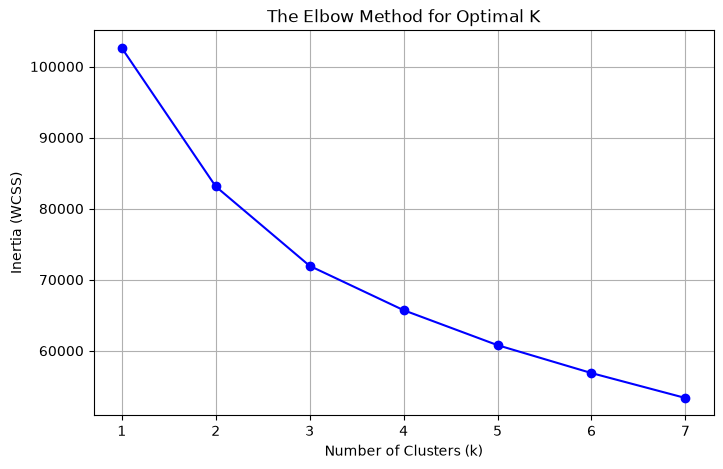

In [114]:
# -------------------------------------------------------------------------
# Step 3: Find Optimal Clusters (The Elbow Method)
# What this does: Calculates WCSS (Within-Cluster Sum of Squares) for different 
# values of k so we can visualize the "elbow" point.
# -------------------------------------------------------------------------
inertia = []
K_range = range(1, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plotting the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.grid(True)
plt.savefig('elbow_curve.png') # Saves the plot to your folder
print("Elbow curve generated and saved as 'elbow_curve.png'.")

In [115]:
# -------------------------------------------------------------------------
# Step 4: Apply K-Means with Optimal K (Let's choose k=4 for now)
# What this does: Groups our customers into 4 distinct behavioural clusters 
# and saves the assigned cluster ID back into our main dataframe.
# -------------------------------------------------------------------------
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

print(f"K-Means applied with k={optimal_k}. Cluster distribution:")
print(df['Cluster'].value_counts())
print("\nTask 3 completed successfully! Ready for Task 4: Predictive Modeling.")

K-Means applied with k=4. Cluster distribution:
Cluster
3    4980
0    4450
1    4138
2    3533
Name: count, dtype: int64

Task 3 completed successfully! Ready for Task 4: Predictive Modeling.


In [116]:
# =========================================================================
# TASK 4: PREDICTIVE MODELLING
# =========================================================================
print("\n--- STARTING TASK 4: PREDICTIVE MODELLING ---")

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np


--- STARTING TASK 4: PREDICTIVE MODELLING ---


In [117]:
# -------------------------------------------------------------------------
# Step 1: Define Features (X) and Target (y)
# What this does: Selects what we want to use to predict (X) and what 
# we want to predict (y = Premium Amount).
# -------------------------------------------------------------------------
model_features = [
    'Age', 'Income Level', 'Coverage Amount', 'Customer_Tenure_Days', 
    'Cluster', 'Premium_to_Coverage_Ratio'
]

X_model = df[model_features].copy()
y_model = df['Premium Amount']

print(f"Features selected for modeling: {model_features}")

Features selected for modeling: ['Age', 'Income Level', 'Coverage Amount', 'Customer_Tenure_Days', 'Cluster', 'Premium_to_Coverage_Ratio']


In [118]:
# -------------------------------------------------------------------------
# Step 2: Train-Test Split
# What this does: Splits data into 80% for training the model and 20% 
# for testing its performance on unseen data.
# -------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.2, random_state=42
)
print(f"Training set shape: {X_train.shape}, Testing set shape: {X_test.shape}")

Training set shape: (13680, 6), Testing set shape: (3421, 6)


In [119]:
# -------------------------------------------------------------------------
# Step 3: Train the Model (Random Forest Regressor)
# What this does: Trains an ensemble of decision trees to learn the complex 
# relationships between customer attributes and their premium amounts.
# -------------------------------------------------------------------------
print("Training Random Forest Regressor...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print("Model training complete.")

Training Random Forest Regressor...


Model training complete.


In [120]:
# -------------------------------------------------------------------------
# Step 4: Make Predictions & Evaluate (Task 5 preview)
# What this does: Evaluates how close our model's predictions are to the 
# actual test values using RMSE and R-squared.
# -------------------------------------------------------------------------
y_pred = rf_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n--- MODEL EVALUATION METRICS ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")
print("\nTask 4 & 5 modeling and evaluation completed successfully!")


--- MODEL EVALUATION METRICS ---
Root Mean Squared Error (RMSE): 31.98
R-squared (R2) Score: 0.9994

Task 4 & 5 modeling and evaluation completed successfully!


In [122]:
# =========================================================================
# FINAL STEP: EXPORT PROCESSED DATA
# =========================================================================
print("\n--- EXPORTING PROCESSED DATA ---")

# Save the dataframe with customer clusters and predictions to a new CSV file
output_filename = 'customer_segmented_predictions.csv'
df.to_csv(output_filename, index=False)

print(f"Processed dataset successfully saved as '{output_filename}'.")
print("Project pipeline completed from end to end!")


--- EXPORTING PROCESSED DATA ---
Processed dataset successfully saved as 'customer_segmented_predictions.csv'.
Project pipeline completed from end to end!
